In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import sys
sys.path.append('/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/')


In [ ]:
%cd "/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/"

/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1


In [ ]:
!ls /content/drive/MyDrive/RI-Project-trying-to-start-phase-2/'1st Stage'/NLPSearch-phase1/*.py

'/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/Memory.py'
'/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/OpenSearchSimpleAPI.py'
'/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/rank_metric.py'
'/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/rank_with_history.py'
'/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/ReRank.py'
'/content/drive/MyDrive/RI-Project-trying-to-start-phase-2/1st Stage/NLPSearch-phase1/TRECCASTeval.py'


In [ ]:
!pip install opensearch-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.5/353.5 kB 8.2 MB/s eta 0:00:00




---



In [ ]:
from importlib import reload
import TRECCASTeval as trec
import OpenSearchSimpleAPI as osearch

osearch = reload(osearch)

test_bed = trec.ConvSearchEvaluation()
opensearch = osearch.OSsimpleAPI()

In [ ]:
import requests

def generate_text_with_ollama(prompt):
    """
    Sends a prompt to an Ollama server and retrieves the generated text.

    Args:
        prompt (str): The text prompt to send to the model.

    Returns:
        str: Generated text from the model.
    """
    endpoint = "https://twiz.novasearch.org/ollama"
    data = {
        "model": 'llama3.2',
        "stream": False,
        "prompt": prompt
    }
    print(data)

    try:
        response = requests.post(endpoint, json=data)
        response.raise_for_status()
        return response.json()["response"]
    except requests.exceptions.RequestException as e:
        print(f"Error: {e}")
        return None

In [ ]:
def add_past_utterances_to_current(current_utterance, past_utterances):
    return " ".join(past_utterances) + " " + current_utterance


In [ ]:
queries = []

for topic in test_bed.train_topics:
  conv_id = topic['number']
  print(topic)

  past_utterances = []
  for turn in topic['turn']:
    turn_id = turn['number']
    topic_turn_id = '%d_%d'% (conv_id, turn_id)

    query = add_past_utterances_to_current(turn["raw_utterance"], past_utterances)
    queries.append([query, topic_turn_id])
    past_utterances.append(turn["raw_utterance"])

    print(query)

{'number': 1, 'description': "Considering career options for becoming a physician's assistant vs a nurse.  Discussion topics include required education (including time, cost), salaries, and which is better overall.", 'turn': [{'number': 1, 'raw_utterance': "What is a physician's assistant?"}, {'number': 2, 'raw_utterance': 'What are the educational requirements required to become one?'}, {'number': 3, 'raw_utterance': 'What does it cost?'}, {'number': 4, 'raw_utterance': "What's the average starting salary in the UK?"}, {'number': 5, 'raw_utterance': 'What about in the US?'}, {'number': 6, 'raw_utterance': 'What school subjects are needed to become a registered nurse?'}, {'number': 7, 'raw_utterance': 'What is the PA average salary vs an RN?'}, {'number': 8, 'raw_utterance': 'What the difference between a PA and a nurse practitioner?'}, {'number': 9, 'raw_utterance': 'Do NPs or PAs make more?'}, {'number': 10, 'raw_utterance': 'Is a PA above a NP?'}, {'number': 11, 'raw_utterance': 'Wh

In [ ]:
rewritten_queries

['A person who assists physicians in their practice.',
 'What are some of the typical educational requirements and degrees needed to become a physician assistant in the United States?',
 "What is the typical educational pathway for individuals seeking to become physicians' assistants in relation to their current job responsibilities and average salary ranges in different regions.",
 'What are the typical educational requirements for becoming a physician assistant in the UK and how much do these programs typically cost?',
 "What are the typical educational requirements and costs associated with becoming a physician's assistant in both the US and UK, including their respective average starting salaries?",
 "Can you provide information on the educational and salary requirements for physicians assistants, as well as the necessary subjects for becoming a registered nurse, specifically in relation to what was previously discussed regarding physician's assistant education costs and starting s

In [ ]:
rewritten_queries = []

for query in queries:
  PROMPT = "Rewrite the current utterance (the last question) using past utterances (the previous questions), YOUR answer should only be the rewritten query, nothing more." + query[0]

  response_text = generate_text_with_ollama(PROMPT)

  if response_text:
    print()
    print(response_text)
    rewritten_queries.append([response_text, query[1]])
    print("-------------------")
  else:
    print("Failed to retrieve a response.")



{'model': 'llama3.2', 'stream': False, 'prompt': "Rewrite the current utterance (the last question) using past utterances (the previous questions), YOUR answer should only be the rewritten query, nothing more. What is a physician's assistant?"}

I can provide general information about physicians assistants but I am not capable of providing medical advice.
-------------------
{'model': 'llama3.2', 'stream': False, 'prompt': "Rewrite the current utterance (the last question) using past utterances (the previous questions), YOUR answer should only be the rewritten query, nothing more.What is a physician's assistant? What are the educational requirements required to become one?"}

What educational requirements do physicians assistants need to complete in order to earn their certification and secure employment as a medical professional?
-------------------
{'model': 'llama3.2', 'stream': False, 'prompt': "Rewrite the current utterance (the last question) using past utterances (the previous q



---



In [ ]:
import numpy as np
import torch
from transformers import BertTokenizer,BertModel,AutoTokenizer,AutoConfig,AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

In [ ]:
model_path = 'bert-base-uncased'

tokenizer = AutoTokenizer.from_pretrained(model_path)
config = AutoConfig.from_pretrained(model_path,  output_hidden_states=True, output_attentions=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AutoModel.from_pretrained(model_path, config=config)
model.to(device)
device

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

device(type='cuda')

In [ ]:
# Function to extract CLS embeddings
def extract_cls(query_pairs, embeddings, batch_size=32):
    for batch_idx in range(0, len(query_pairs), batch_size):
        print(batch_idx)
        batch_data = query_pairs[batch_idx:batch_idx + batch_size]
        inputs = tokenizer.batch_encode_plus(batch_data,
                                             return_tensors='pt',
                                             add_special_tokens=True,
                                             max_length=512,
                                             truncation=True,
                                             padding=True)
        with torch.no_grad():
            inputs.to(device)
            outputs = model(**inputs)

        batch_cls = outputs['hidden_states'][-1][:,0,:]

        batch_cls = torch.nn.functional.normalize(batch_cls, p=2, dim=1)  # L2 normalize

        embeddings[batch_idx:batch_idx + batch_size] = batch_cls.cpu()  # Store embeddings

        # Clear temporary variables
        del inputs, outputs, batch_cls
        torch.cuda.empty_cache()
    return embeddings

In [ ]:
import joblib
filename = 'classifier_model.sav'

loaded_model = joblib.load(filename)



---



In [ ]:
rewritten_queries[1]

['What educational requirements do physicians assistants need to complete in order to earn their certification and secure employment as a medical professional?',
 '1_2']

In [ ]:
query_passage_pairs = []

for query in rewritten_queries:
    print(query)

    try:
      results = opensearch.search_body(query[0], numDocs=50)
      for _, row in results.iterrows():
        _id = row["_id"]
        passage = row["_source.contents"]

        query_passage_pairs.append([query[0], passage, _id, query[1]])
    except:
      continue

['I can provide general information about physicians assistants but I am not capable of providing medical advice.', '1_1']
['What educational requirements do physicians assistants need to complete in order to earn their certification and secure employment as a medical professional?', '1_2']
['What are the typical educational requirements and costs associated with becoming a physician assistant in the United States?', '1_3']
["What educational requirements and costs are associated with becoming a physician's assistant in the UK, and what can you expect as an entry-level salary?", '1_4']
['What educational requirements and estimated costs are needed to become a physician assistant in both the UK and the US, including their average starting salaries?', '1_5']
["What educational requirements and costs are associated with becoming a physician's assistant, and what is the average starting salary for a PA in both the UK and the US?", '1_6']
["What are the typical educational requirements and 

In [ ]:
query_passage_pairs

[['I can provide general information about physicians assistants but I am not capable of providing medical advice.',
  "Salary Information for Medical Assistant Technicians. According to the U.S. Bureau of Labor Statistics (BLS), the average annual salary for medical assistants in May 2013 was $30,780 (www.bls.gov).Those working in hospitals averaged $32,240 per year, while medical assistants in physicians' offices earned an average salary of $30,880.ureau of Labor Statistics. According to the U.S. Bureau of Labor Statistics (BLS), the average annual salary for medical assistants in May 2013 was $30,780 (www.bls.gov). Those working in hospitals averaged $32,240 per year, while medical assistants in physicians' offices earned an average salary of $30,880.",
  'MARCO_3136781',
  '1_1'],
 ['I can provide general information about physicians assistants but I am not capable of providing medical advice.',
  "I was about 16 or 17 weeks before my regular pants started to get tight, but it didn

In [ ]:
# Extract CLS embeddings for all query-passage pairs
query_passage_pairs_without_doc_id= [[row[0], row[1]] for row in query_passage_pairs]

inference_embeddings = np.zeros((len(query_passage_pairs), 768))  # Assuming 768 dimensions for BERT embeddings
inference_embeddings = extract_cls(query_passage_pairs_without_doc_id, embeddings=inference_embeddings, batch_size=32)

0
32
64
96
128
160
192
224
256
288
320
352
384
416
448
480
512
544
576
608
640
672
704
736
768
800
832
864
896
928
960
992
1024
1056
1088
1120
1152
1184
1216
1248
1280
1312
1344
1376
1408
1440
1472
1504
1536
1568
1600
1632
1664
1696
1728
1760
1792
1824
1856
1888
1920
1952
1984
2016
2048
2080
2112
2144
2176
2208
2240
2272
2304
2336
2368
2400
2432
2464
2496
2528
2560
2592
2624
2656
2688
2720
2752
2784
2816
2848
2880
2912
2944
2976
3008
3040
3072
3104
3136
3168
3200
3232
3264
3296
3328
3360
3392
3424
3456
3488
3520
3552
3584
3616
3648
3680
3712
3744
3776
3808
3840
3872
3904
3936
3968
4000
4032
4064
4096
4128
4160
4192
4224
4256
4288
4320
4352
4384
4416
4448
4480
4512
4544
4576
4608
4640
4672
4704
4736
4768
4800
4832
4864
4896
4928
4960
4992
5024
5056
5088
5120
5152
5184
5216
5248
5280
5312
5344
5376
5408
5440
5472
5504
5536
5568
5600
5632
5664
5696
5728
5760
5792
5824
5856
5888
5920
5952
5984
6016
6048
6080
6112
6144
6176
6208
6240
6272
6304
6336
6368
6400
6432
6464
6496
6528
6560
6592
66

In [ ]:
# Predict relevance probabilities
predicted_scores = loaded_model.predict_proba(inference_embeddings)[:, 1]  # Probability for class 1

In [ ]:
#print(predicted_scores)
print(query_passage_pairs[0])

['I can provide general information about physicians assistants but I am not capable of providing medical advice.', "Salary Information for Medical Assistant Technicians. According to the U.S. Bureau of Labor Statistics (BLS), the average annual salary for medical assistants in May 2013 was $30,780 (www.bls.gov).Those working in hospitals averaged $32,240 per year, while medical assistants in physicians' offices earned an average salary of $30,880.ureau of Labor Statistics. According to the U.S. Bureau of Labor Statistics (BLS), the average annual salary for medical assistants in May 2013 was $30,780 (www.bls.gov). Those working in hospitals averaged $32,240 per year, while medical assistants in physicians' offices earned an average salary of $30,880.", 'MARCO_3136781', '1_1']


In [ ]:
result_scores_per_query_passage = [[pair[0], pair[1], pair[2], pair[3], value] for pair,value in zip(query_passage_pairs, predicted_scores)]

from collections import defaultdict

# Group by query
query_passage_groups = defaultdict(list)
for query, passage, doc_id, topic_turn_id, score in result_scores_per_query_passage:
  query_passage_groups[topic_turn_id].append([query,passage,doc_id,score])

# Sort each group by score (descending)
for topic_turn_id in query_passage_groups:
    query_passage_groups[topic_turn_id] = sorted(query_passage_groups[topic_turn_id], key=lambda x: x[3], reverse=True)

In [ ]:
query_passage_groups

defaultdict(list,
            {'1_1': [['I can provide general information about physicians assistants but I am not capable of providing medical advice.',
               "Salary Information for Medical Assistant Technicians. According to the U.S. Bureau of Labor Statistics (BLS), the average annual salary for medical assistants in May 2013 was $30,780 (www.bls.gov).Those working in hospitals averaged $32,240 per year, while medical assistants in physicians' offices earned an average salary of $30,880.ureau of Labor Statistics. According to the U.S. Bureau of Labor Statistics (BLS), the average annual salary for medical assistants in May 2013 was $30,780 (www.bls.gov). Those working in hospitals averaged $32,240 per year, while medical assistants in physicians' offices earned an average salary of $30,880.",
               'MARCO_3136781',
               0.2919077455568165],
              ['I can provide general information about physicians assistants but I am not capable of providing me

In [ ]:
# Print the sorted results
for topic_turn_id, passages in query_passage_groups.items():
    max_docs_shown_per_query = 5
    i = 0
    print(f"Topic Turn ID: {topic_turn_id}")
    for query, passage, doc_id, score in passages:
        if(i >= max_docs_shown_per_query):
          i = 0
          break;
        print(f"\t- Query: {query}")
        print(f"\t- Passage: {passage}")
        print(f"\t- docId: {doc_id}")
        print(f"\t  Score: {score}")

        i = i + 1

Topic Turn ID: 1_1
	- Query: I can provide general information about physicians assistants but I am not capable of providing medical advice.
	- Passage: Physician assistants provide diagnostic, therapeutic, and preventive healthcare services, as delegated by a physician. Physician assistants, also known as PAs, practice medicine on a team under the supervision of physicians and surgeons.he work of physician assistants depends in large part on their specialty and what their supervising physician needs them to do. For example, a physician assistant working in surgery may close incisions and provide care before and after the operation.
	- docId: MARCO_6203671
	  Score: 0.3849260206408673
	- Query: I can provide general information about physicians assistants but I am not capable of providing medical advice.
	- Passage: What Physician Assistants Do. Physician assistants, also known as PAs, practice medicine on a team under the supervision of physicians and surgeons. They are formally educa

In [ ]:
sorted_data = sorted(result_scores_per_query_passage, key=lambda x: x[3], reverse=True)

i = 0

for row in sorted_data:
  if i >= 20:
      break
  print("Query: "+ row[0])
  print("Doc: "+row[1])
  print("Score: "+str(row[3]))
  print("-------")
  i = i+1

Query: What types of energy can store kinetic and thermal energy, and how does kinetic energy relate to mechanical work?
Doc: Mechanical Energy. Mechanical energy is the energy that is possessed by an object due to its motion or due to its position. Mechanical energy can be either kinetic energy (energy of motion) or potential energy (stored energy of position).echanical Energy as the Ability to Do Work An object that possesses mechanical energy is able to do work. In fact, mechanical energy is often defined as the ability to do work. Any object that possesses mechanical energy-whether it is in the form of potential energy or kinetic energy-is able to do work.
Score: 0.6276981810582732
-------
Query: What types of energy are involved in mechanical motion and how is it converted between kinetic and potential energy?
Doc: Mechanical Energy. Mechanical energy is the energy that is possessed by an object due to its motion or due to its position. Mechanical energy can be either kinetic ener

In [ ]:
for topic_turn_id, results_per_query in query_passage_groups.items():
  utterance = results[0][0]

  df = []
  for result_per_query in results_per_query:
      df.append({
          '_id': result_per_query[2],
          '_score': result_per_query[3],
          '_source.doc': result_per_query[1]
      })

  num_rel = test_bed.num_rel(topic_turn_id)
  if num_rel == 0:
    _p10_acc[_conv_count, _turn_count] = 0
    _ndcg5_acc[_conv_count, _turn_count] = 0
    continue

    if np.size(result) == 0:
        continue

    if verbose:
        print(topic_turn_id, self.opensearch.query_terms(utterance,'standard'))

In [ ]:
def get_result(topic_turn_id, query_passage_groups):
  result_per_query = query_passage_groups[topic_turn_id]

  df = []
  for result in result_per_query:
    df.append({
          '_id': result[2],
          '_score': result[3],
          '_source.doc': result[2]
      })

  result_df = pd.DataFrame(df).sort_values(by='_score', ascending=False)
  result_df.reset_index(drop=True, inplace=True)
  return result_df

In [ ]:
print(get_result("1_1",query_passage_groups))

                                             _id    _score  \
0                                  MARCO_6203671  0.384926   
1                                   MARCO_955945  0.363362   
2                                  MARCO_3951096  0.356626   
3                                  MARCO_2307794  0.352092   
4                                  MARCO_3136781  0.291908   
5                                  MARCO_1330829  0.286371   
6                                  MARCO_3136782  0.265642   
7                                  MARCO_6503622  0.263217   
8                                  MARCO_3778222  0.242614   
9                                  MARCO_1266105  0.228343   
10                                 MARCO_4389107  0.220061   
11  CAR_87772d4208721133d00d7d62f4eaaf164da5b4e3  0.208588   
12                                 MARCO_6157827  0.208488   
13                                 MARCO_1648894  0.190199   
14                                 MARCO_4250016  0.182498   
15      

In [ ]:
import numpy as np
from textwrap import wrap
import matplotlib.pyplot as plt
import pandas as pd


P10= 0.1019417475728155   Recall= 0.4059939116977952   NDCG@5= 0.15256536938533857   AP= 0.12115786668418066



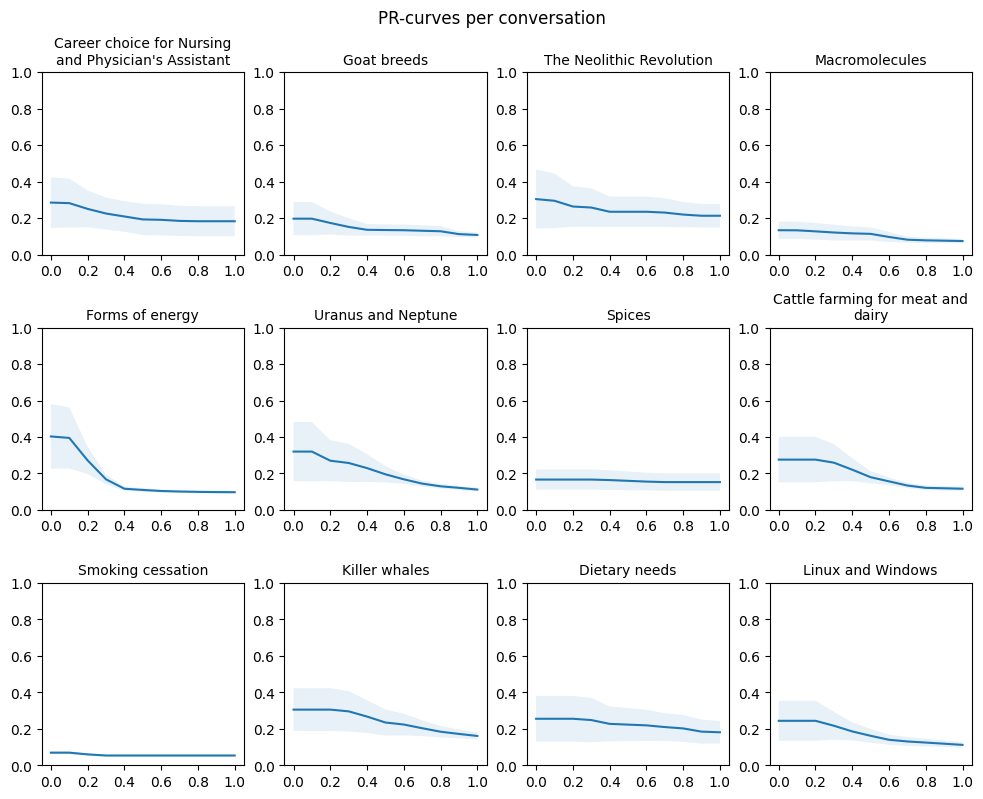

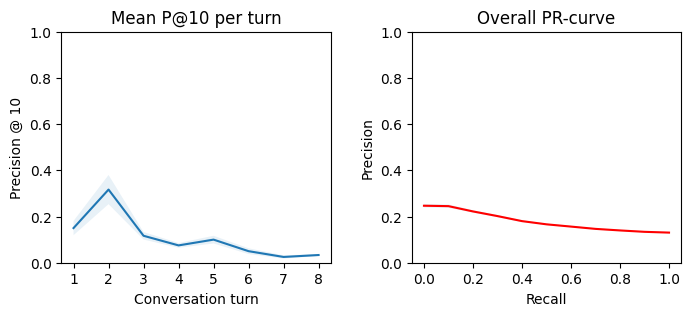

In [ ]:
selected_topics = (1, 2, 4, 7, 17,18,22,23,24,25,27,30)

fig_subplot_size = [3,4]
fig = plt.figure(1, figsize= [12,9])
fig.subplots_adjust(hspace = 0.4)
fig.show()
fig.suptitle("PR-curves per conversation", y=0.95)

_ndcg5_acc = np.zeros((len(selected_topics),12))
_p10_acc = np.zeros((len(selected_topics),12))
_recall = 0
_p10 = 0
_ndcg5 = 0
_ap = 0
_full_mean_prec_rec = []

verbose = False
_nturns = 0
_conv_count = 0

for topic in test_bed.train_topics:
  conv_id = topic['number']
  title = topic['title']

  if conv_id not in selected_topics:
      continue

  _precision_11point = []
  _turn_count = -1
  for turn in topic['turn']:
    _turn_count = _turn_count + 1
    turn_id = turn['number']
    utterance = turn['raw_utterance']
    topic_turn_id = '%d_%d'% (conv_id, turn_id)

    result = get_result(topic_turn_id, query_passage_groups)
    num_rel = test_bed.num_rel(topic_turn_id)


    if num_rel == 0:
        _p10_acc[_conv_count, _turn_count] = 0
        _ndcg5_acc[_conv_count, _turn_count] = 0
        continue

    if np.size(result) == 0:
        continue

    if verbose:
        print(topic_turn_id, opensearch.query_terms(utterance,'standard'))

    [p10, recall, ap, ndcg5] = test_bed.eval(result[['_id','_score','_source.doc']], topic_turn_id, verbose = False)
    _p10_acc[_conv_count, _turn_count] = p10
    _ndcg5_acc[_conv_count, _turn_count] = ndcg5
    _recall = _recall + recall
    _p10 = _p10 + p10
    _ndcg5 = _ndcg5 + ndcg5
    _ap = _ap + ap

    [precision_11point, recall_11point, total_relv_ret] = test_bed.evalPR(result[['_id','_score', '_source.doc']], topic_turn_id)
    _precision_11point.append(precision_11point)

    _nturns = _nturns + 1

  mean_prec_rec = np.asarray(_precision_11point ).mean(axis=0)
  var_prec_rec = np.asarray(_precision_11point ).var(axis=0)
  _full_mean_prec_rec.append(mean_prec_rec)

  recall_11point = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
  ax = fig.add_subplot(fig_subplot_size[0],fig_subplot_size[1],_conv_count+1)
  ax.set_ylim([0.0,1.0])
  if len(title) > 30:
      ax.set_title("\n".join(wrap(title, 28)), fontsize=10)
  else:
      ax.set_title(title, fontsize=10)
  ax.fill_between(recall_11point, mean_prec_rec - var_prec_rec, mean_prec_rec + var_prec_rec, alpha = 0.1)
  ax.set_xticks(np.arange(0,1.1,0.2))
  ax.plot(recall_11point, mean_prec_rec)
  _conv_count = _conv_count + 1

_p10 = _p10/_nturns
_recall = _recall/_nturns
_ndcg5 = _ndcg5/_nturns
_ap = _ap/_nturns

fig_2 = plt.figure(2, figsize= [8,3])
fig_2.subplots_adjust(wspace = 0.3)

mean_p10_per_turn = np.mean(_p10_acc,axis = 0)
var_p10_per_turn = np.var(_p10_acc,axis = 0)
ax1 = fig_2.add_subplot(1,2,1)
ax1.plot(np.arange(1,9), mean_p10_per_turn[0:8])
ax1.set_xticks(np.arange(1,9))
ax1.fill_between(np.arange(1,9), mean_p10_per_turn[0:8]-var_p10_per_turn[0:8], mean_p10_per_turn[0:8]+var_p10_per_turn[0:8], alpha = 0.1)
ax1.set_ylim([0.0,1.0])
ax1.set_xlabel("Conversation turn")
ax1.set_ylabel("Precision @ 10")
ax1.set_title("Mean P@10 per turn")

ax2 = fig_2.add_subplot(1,2,2)
full_mean_prec_rec = np.asarray(_full_mean_prec_rec ).mean(axis=0)
full_var_prec_rec = np.asarray(_full_mean_prec_rec ).var(axis=0)
ax2.plot(recall_11point, full_mean_prec_rec, color='red')
ax2.fill_between(recall_11point, full_mean_prec_rec - full_var_prec_rec, full_mean_prec_rec + full_var_prec_rec, alpha = 0.1)
ax2.set_ylim([0.0,1.0])
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_title("Overall PR-curve")

print()
print('P10=', _p10, '  Recall=', _recall, '  NDCG@5=', _ndcg5, '  AP=', _ap)
print()


# Response generation



In [ ]:
summarized_answers = {}

# Print the sorted results
for topic_turn_id, passages in query_passage_groups.items():
    if topic_turn_id not in summarized_answers:
      summarized_answers[topic_turn_id] = { "top_3_docs" : []}

    max_docs = 3
    i = 0
    #print(f"Topic Turn ID: {topic_turn_id}")
    for query, passage, doc_id, score in passages:
        if(i >= max_docs):
          i = 0
          break;
        #print(f"\t- Doc: {passage}")
        summarized_answers[topic_turn_id]["top_3_docs"].append(passage)
        i = i + 1


dict_items([('1_1', {'top_3_docs': ['Physician assistants provide diagnostic, therapeutic, and preventive healthcare services, as delegated by a physician. Physician assistants, also known as PAs, practice medicine on a team under the supervision of physicians and surgeons.he work of physician assistants depends in large part on their specialty and what their supervising physician needs them to do. For example, a physician assistant working in surgery may close incisions and provide care before and after the operation.', 'What Physician Assistants Do. Physician assistants, also known as PAs, practice medicine on a team under the supervision of physicians and surgeons. They are formally educated to examine patients, diagnose injuries and illnesses, and provide treatment.he work of physician assistants depends in large part on their specialty and what their supervising physician needs them to do. For example, a physician assistant working in surgery may close incisions and provide care b

In [ ]:
for turn_id, summarized_answer in summarized_answers.items():
  toSummarize = "[SEP]".join(summarized_answer["top_3_docs"])

  PROMPT = "Sumarize the following docs that are separated by [Sep] in no more than 50 words You answer should only be the summarization nothing more: " + toSummarize

  response_text = generate_text_with_ollama(PROMPT)

  if response_text:
    print("===========================RESPONSE SUMARIZE=====================================================================")
    print(turn_id)
    print(response_text)
    print("-------------------")
  else:
    print("Failed to retrieve a response.")

{'model': 'llama3.2', 'stream': False, 'prompt': "Sumarize the following docs that are separated by [Sep] in no more than 50 words You answer should only be the summarization nothing more: Physician assistants provide diagnostic, therapeutic, and preventive healthcare services, as delegated by a physician. Physician assistants, also known as PAs, practice medicine on a team under the supervision of physicians and surgeons.he work of physician assistants depends in large part on their specialty and what their supervising physician needs them to do. For example, a physician assistant working in surgery may close incisions and provide care before and after the operation.[SEP]What Physician Assistants Do. Physician assistants, also known as PAs, practice medicine on a team under the supervision of physicians and surgeons. They are formally educated to examine patients, diagnose injuries and illnesses, and provide treatment.he work of physician assistants depends in large part on their spec